In [1]:
import sys, math, os
import logging
import numpy as np
from ase.io import read, write
from os import environ, listdir, mkdir, chdir
from ase.units import Hartree, Bohr
from os import path
from ase import Atoms
import json
from ase.io import read
import h5py

In [6]:
EPBE0_atom = {1:-13.64136507, 6:-1027.59344601, \
              7:-1484.25358313, 8:-2039.74560236, 9: -3139.751675679, 15:-9283.01120606, 16: -10828.726222083, 17: -12516.462339357}

filtered_dir = "/data/horse/ws/miha493e-research_project/activediffusion/datasets/iter_0/filtered"         # input directory with filtered molecules
h5file_curr = "/data/horse/ws/miha493e-research_project/activediffusion/datasets/iter_0/hdf5/test_output.hdf5"            # output file path of current iteration
h5file_full = "/data/horse/ws/miha493e-research_project/activediffusion/datasets/hdf5/test_qm7x-aqm-gas-noP-output.hdf5"          # output file path of full generated dataset
itr = 0

In [7]:
folders = sorted(listdir(filtered_dir))


In [ ]:
with h5py.File(h5file_curr, 'w') as iter_h5file, h5py.File(h5file_full, 'a') as full_h5file:
    for hdf5_file in [iter_h5file, full_h5file]:

        for fdir in folders:

            print(fdir)
            grp = hdf5_file.create_group(f"{fdir}_{itr}")
            molecule = {}

            #folders2 = sorted(listdir(xyz_pre+fdir))
            folder_path = os.path.join(filtered_dir, fdir)
            jfils = [f for f in listdir(folder_path) if f.endswith('.json')]  #As folder have non json files

            for confid in jfils:

                with open(filtered_dir+'/'+str(fdir)+'/'+str(confid)) as json_file:
                    data = json.load(json_file)

                sysname = confid[:-5]

                subgrp = grp.create_group(sysname)
            #saving DFT data

                # w = len(data["Coordinates"])
                # ftmp = open('tmp-'+str(sysname)+'.xyz', 'w')  # open file for writing
                # ftmp.write(str(w) + "\n")
                # ftmp.write("{: >24}".format('leo') + "\n")
                # for p1 in data["Coordinates"]:
                #     ftmp.write("{: >24} {: >24} {: >24} {: >24}".format(*p1) + "\n")
                # ftmp.close()
                #atoms = read('tmp-'+str(sysname)+'.xyz')    # define atoms
                xyz_file_path = os.path.join(folder_path, sysname + '.xyz')       # path to the xyz file if coordinate is not in json file
                atoms = read(xyz_file_path)
                Z = atoms.get_atomic_numbers()
                POS = atoms.get_positions()

                #os.remove('tmp-'+str(sysname)+'.xyz')

                ener=float(data["Total energy (eV):"])
                mbd=float(data["SUM"]["MBD"])
                pbe0 = float(ener) - float(mbd)
                #print("EPBE0_atom keys:", EPBE0_atom.keys())
                #print("Z values:", Z)
                #print([type(zi) for zi in Z])
                EDFTatoms = sum([ EPBE0_atom[zi] for zi in Z ])
                Eat = float(pbe0) - float(EDFTatoms)

                totfor = np.array(data["Total Forces (eV/Ang):"])
                vdwfor = np.array(data["van der Waals Forces (eV/Ang):"])
                pbe0for = totfor - vdwfor

            #Hirshfeld quantities
                HChar = np.array(data["Hirshfeld Charges:"])

            #DIPOLE moment
    #            dipole = float(data["Absolute Total Dipole (eAng):"])
    #            dipcomp = np.array(data["Total Dipole (eAng)"]) 

                FVol = data["Free Atom Volumes:"]
                HVol = data["Hirshfeld Volumes:"]
                hvr = np.divide(HVol,FVol)    # define hirshfeld ratios
                
                molecule['DIP'] = np.array(data["Absolute Total Dipole (eAng):"])
                molecule['HLgap'] = np.array(float(data["HOMO-LUMO gap"]))
                molecule['atNUM'] = np.array(Z)
                molecule['atXYZ'] = np.array(POS)
                molecule['eAT'] = np.array(data["SUM"]["Free atom Elst"]) # or Eat = float(pbe0) - float(EDFTatoms) 
                molecule['eC'] = np.array(data["SUM"]["C energy"])
                molecule['eEE'] = np.array(data["SUM"]["Electrostatic Energy"])
                molecule['eH'] = np.array(data["SUM"]["Hartree-Fock Energy"])
                molecule['eKIN'] = np.array(data["SUM"]["Kinetic Energy"])
                molecule['eMBD'] = np.array(data["SUM"]["MBD"])
                molecule['ePBE0'] = np.array([float(pbe0)])
                molecule['ePBE0+MBD'] = np.array([float(ener)])
                molecule['totFOR'] = totfor
                molecule['pbe0FOR'] = pbe0for
                molecule['eX'] = np.array(data["SUM"]["X energy"])
                molecule['eXC'] = np.array(data["SUM"]["Total XC energy"])
                molecule['eXX'] = np.array(data["SUM"]["Hartree-Fock Energy"])

                for key, value in molecule.items():
                    print(key, value, value.shape, value.dtype)
                    dset = subgrp.create_dataset(key, value.shape, dtype=value.dtype)
                    dset[...] = value

In [3]:
import torch
import numpy as np

In [ ]:
model_path='/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_0/best_mol_stab.ckpt'
hparams = torch.load(model_path)["hyper_parameters"]
print("HYPER PARAMETERS:")
for key, value in hparams.items():
    print(f"{key}: {value} ({type(value)})")
    if isinstance(value, np.ndarray):
        print(f"  Shape: {value.shape}, Dtype: {value.dtype}")
        

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Paths to your 3 files
file1 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_0/relaxed/sascore.txt"
file2 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_1/relaxed/sascore.txt"
file3 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_2/relaxed/sascore.txt"
file4 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_3/relaxed/sascore.txt"
file5 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_4/relaxed/sascore.txt"
file6 = "/data/horse/ws/miha493e-research_project/activediffusion/data/iter_5/relaxed/sascore.txt"

# Read the files, assuming 3 columns with no header
data1 = pd.read_csv(file1, sep=r"\s+", header=None)
data2 = pd.read_csv(file2, sep=r"\s+", header=None)
data3 = pd.read_csv(file3, sep=r"\s+", header=None)
data4 = pd.read_csv(file4, sep=r"\s+", header=None)
data5 = pd.read_csv(file5, sep=r"\s+", header=None)
data6 = pd.read_csv(file6, sep=r"\s+", header=None)

# Extract only the second column (SAScore)
sas1 = data1[1]
sas2 = data2[1]
sas3 = data3[1]
sas4 = data4[1]
sas5 = data5[1]
sas6 = data6[1]

import seaborn as sns

plt.figure(figsize=(10, 6))
sns.kdeplot(sas1, label='iteration 1', fill=True)
sns.kdeplot(sas2, label='iteration 2', fill=True)
sns.kdeplot(sas3, label='iteration 3', fill=True)
sns.kdeplot(sas4, label='iteration 4', fill=True)
sns.kdeplot(sas5, label='iteration 5', fill=True)
sns.kdeplot(sas6, label='iteration 6', fill=True)

plt.xlabel('SAScore')
plt.ylabel('Density')
plt.title('SAScore Distribution from 6 Iterations')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_iteration_data_from_paths(file_paths):
    all_dfs = []
    for i, path in enumerate(file_paths):
        with open(path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        # Extract header and data line
        data_lines = [line for line in lines if not line.startswith(',mol_stable')]
        if not data_lines:
            continue

        header_line = [line for line in lines if line.startswith(',mol_stable')][0]
        header = header_line.lstrip(',').split(',')
        values = data_lines[0].lstrip(',').split(',')[1:]

        df = pd.DataFrame([values], columns=header)
        df["iteration"] = i
        df["filename"] = path
        all_dfs.append(df)

    combined_df = pd.concat(all_dfs, ignore_index=True)
    
    # Convert all columns (except filename) to numeric if possible
    for col in combined_df.columns:
        if col not in ["filename"]:
            combined_df[col] = pd.to_numeric(combined_df[col], errors='ignore')

    return combined_df


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import math

def plot_metrics_subplots(df, metrics):
    """
    Plots multiple metrics from a DataFrame on separate subplots.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        metrics (list): A list of strings, where each string is a column name
                        representing a metric to be plotted.
    """
    if "iteration" not in df.columns:
        print("Column 'iteration' not found in data.")
        return

    existing_metrics = [metric for metric in metrics if metric in df.columns]
    non_existing_metrics = [metric for metric in metrics if metric not in df.columns]

    if non_existing_metrics:
        print(f"Metrics not found in data and will be skipped: {', '.join(non_existing_metrics)}")

    if not existing_metrics:
        print("No valid metrics found to plot.")
        return

    df_sorted = df.sort_values("iteration")
    num_metrics = len(existing_metrics)

    # Determine the grid size for the subplots
    # We'll use a square-ish layout for better visual appeal (e.g., 4 metrics -> 2x2 grid)
    num_cols = int(math.ceil(math.sqrt(num_metrics)))
    num_rows = int(math.ceil(num_metrics / num_cols))

    # Create the figure and a grid of subplots
    # sharex=True ensures that all x-axes are linked, making it easy to compare iterations
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 4 * num_rows), sharex=True)
    
    # Flatten the axes array if it's 2D for easier iteration
    axes = axes.flatten() if isinstance(axes, (list, tuple, object)) else [axes]

     # Colors from seaborn palette
    palette = sns.color_palette("tab10", len(metrics))

    # Plot each metric on its own subplot
    for i, metric in enumerate(existing_metrics):
        axes[i].plot(df_sorted["iteration"], df_sorted[metric], marker='o', color=palette[i], linewidth=2)
        axes[i].set_title(metric, fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Iteration', fontsize=10)
        axes[i].set_ylabel(metric, fontsize=10)
        axes[i].grid(True, linestyle='--', alpha=0.6)
    
    # Set a common x-label for the entire figure to avoid clutter
    fig.supxlabel("Iteration", fontsize=12)
    fig.suptitle("Metrics over Iterations", fontsize=16)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)



    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
    plt.show()


In [ ]:
# List your file paths in the correct iteration order
file_paths = [
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_0/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_1/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_2/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_3/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_4/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_5/run0/evaluation.csv",
    "/data/horse/ws/miha493e-research_project/activediffusion/data/diffusion_wdir/model_registry/model_iter_6/run0/evaluation.csv",
]

df = load_iteration_data_from_paths(file_paths)
metrics = ['mol_stable', 'atm_stable', 'validity', 'sanitize_validity',
           'novelty', 'kl_score', 'QED', 'Diversity']
plot_metrics_subplots(df, metrics)

### view sascore distributions

In [26]:
# Base directory
base_dir = "/data/horse/ws/miha493e-research_project/activediffusion/data/data_80"

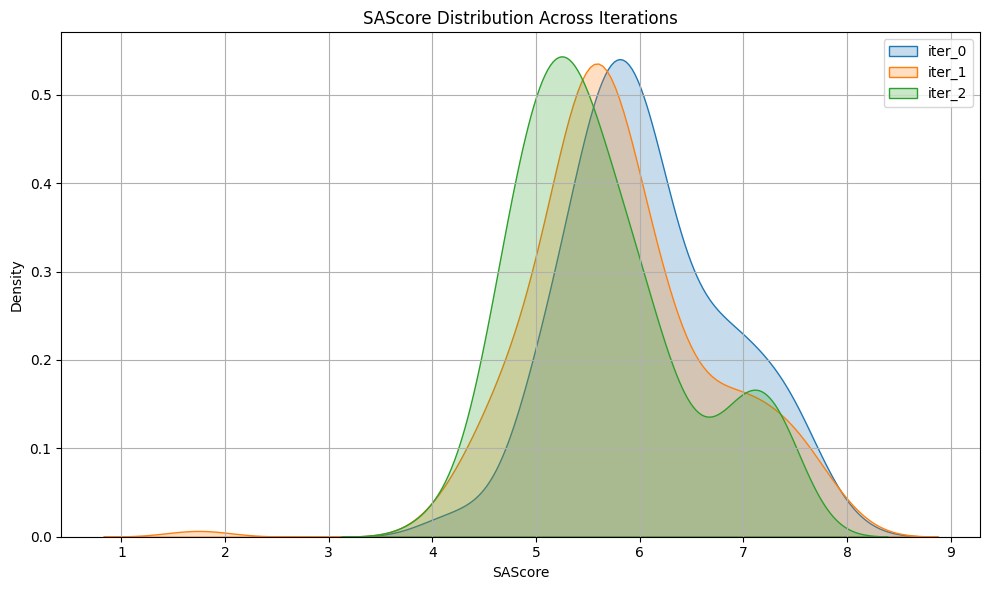

⚠ Missing files:
/data/horse/ws/miha493e-research_project/activediffusion/data/data_80/iter_3/relaxed/sascore.txt


In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re


plt.figure(figsize=(10, 6))

missing_files = []

# Loop over all iteration folders
for iter_num in sorted(
    [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    sas_file = os.path.join(base_dir, iter_num, "relaxed", "sascore.txt")
    
    if os.path.exists(sas_file):
        data = pd.read_csv(sas_file, sep=r"\s+", header=None)
        sas = data[1]  # Second column
        sns.kdeplot(sas, label=f'{iter_num}', fill=True)
    else:
        missing_files.append(sas_file)

plt.xlabel('SAScore')
plt.ylabel('Density')
plt.title('SAScore Distribution Across Iterations')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Report missing files if any
if missing_files:
    print("⚠ Missing files:")
    for f in missing_files:
        print(f)


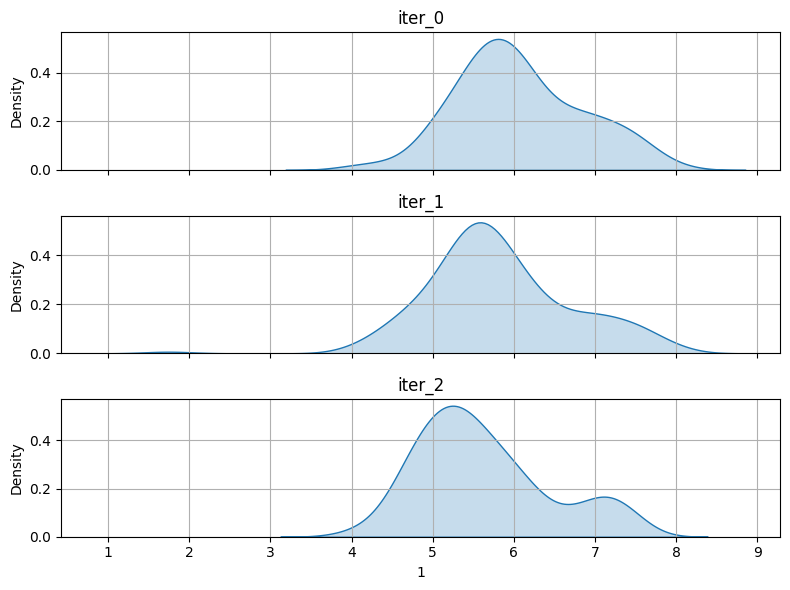

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re

# Collect data
sas_data = []
iterations = []

for iter_num in sorted(
    [d for d in os.listdir(base_dir) if re.match(r"iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    sas_file = os.path.join(base_dir, iter_num, "relaxed", "sascore.txt")
    if os.path.exists(sas_file):
        data = pd.read_csv(sas_file, sep=r"\s+", header=None)
        sas_data.append(data[1])
        iterations.append(iter_num)

# Create subplots
fig, axes = plt.subplots(len(sas_data), 1, figsize=(8, 2*len(sas_data)), sharex=True)

for ax, sas, label in zip(axes, sas_data, iterations):
    sns.kdeplot(sas, fill=True, ax=ax)
    ax.set_title(label)
    ax.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_iteration_data_from_paths(file_paths):
    all_dfs = []
    for i, path in enumerate(file_paths):
        with open(path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        # Extract header and data line
        data_lines = [line for line in lines if not line.startswith(',mol_stable')]
        if not data_lines:
            continue

        header_line = [line for line in lines if line.startswith(',mol_stable')][0]
        header = header_line.lstrip(',').split(',')
        values = data_lines[0].lstrip(',').split(',')[1:]

        df = pd.DataFrame([values], columns=header)
        df["iteration"] = i
        df["filename"] = path
        all_dfs.append(df)

    combined_df = pd.concat(all_dfs, ignore_index=True)
    
    # Convert all columns (except filename) to numeric if possible
    for col in combined_df.columns:
        if col not in ["filename"]:
            combined_df[col] = pd.to_numeric(combined_df[col], errors='ignore')

    return combined_df


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import math

def plot_metrics_subplots(df, metrics):
    """
    Plots multiple metrics from a DataFrame on separate subplots.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        metrics (list): A list of strings, where each string is a column name
                        representing a metric to be plotted.
    """
    if "iteration" not in df.columns:
        print("Column 'iteration' not found in data.")
        return

    existing_metrics = [metric for metric in metrics if metric in df.columns]
    non_existing_metrics = [metric for metric in metrics if metric not in df.columns]

    if non_existing_metrics:
        print(f"Metrics not found in data and will be skipped: {', '.join(non_existing_metrics)}")

    if not existing_metrics:
        print("No valid metrics found to plot.")
        return

    df_sorted = df.sort_values("iteration")
    num_metrics = len(existing_metrics)

    # Determine the grid size for the subplots
    # We'll use a square-ish layout for better visual appeal (e.g., 4 metrics -> 2x2 grid)
    num_cols = int(math.ceil(math.sqrt(num_metrics)))
    num_rows = int(math.ceil(num_metrics / num_cols))

    # Create the figure and a grid of subplots
    # sharex=True ensures that all x-axes are linked, making it easy to compare iterations
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 4 * num_rows), sharex=True)
    
    # Flatten the axes array if it's 2D for easier iteration
    axes = axes.flatten() if isinstance(axes, (list, tuple, object)) else [axes]

     # Colors from seaborn palette
    palette = sns.color_palette("tab10", len(metrics))

    # Plot each metric on its own subplot
    for i, metric in enumerate(existing_metrics):
        axes[i].plot(df_sorted["iteration"], df_sorted[metric], marker='o', color=palette[i], linewidth=2)
        axes[i].set_title(metric, fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Iteration', fontsize=10)
        axes[i].set_ylabel(metric, fontsize=10)
        axes[i].grid(True, linestyle='--', alpha=0.6)
    
    # Set a common x-label for the entire figure to avoid clutter
    fig.supxlabel("Iteration", fontsize=12)
    fig.suptitle("Metrics over Iterations", fontsize=16)

    # Hide any unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)



    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for suptitle
    plt.show()


/tmp/ipykernel_2253142/2398109983.py:30: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  combined_df[col] = pd.to_numeric(combined_df[col], errors='ignore')


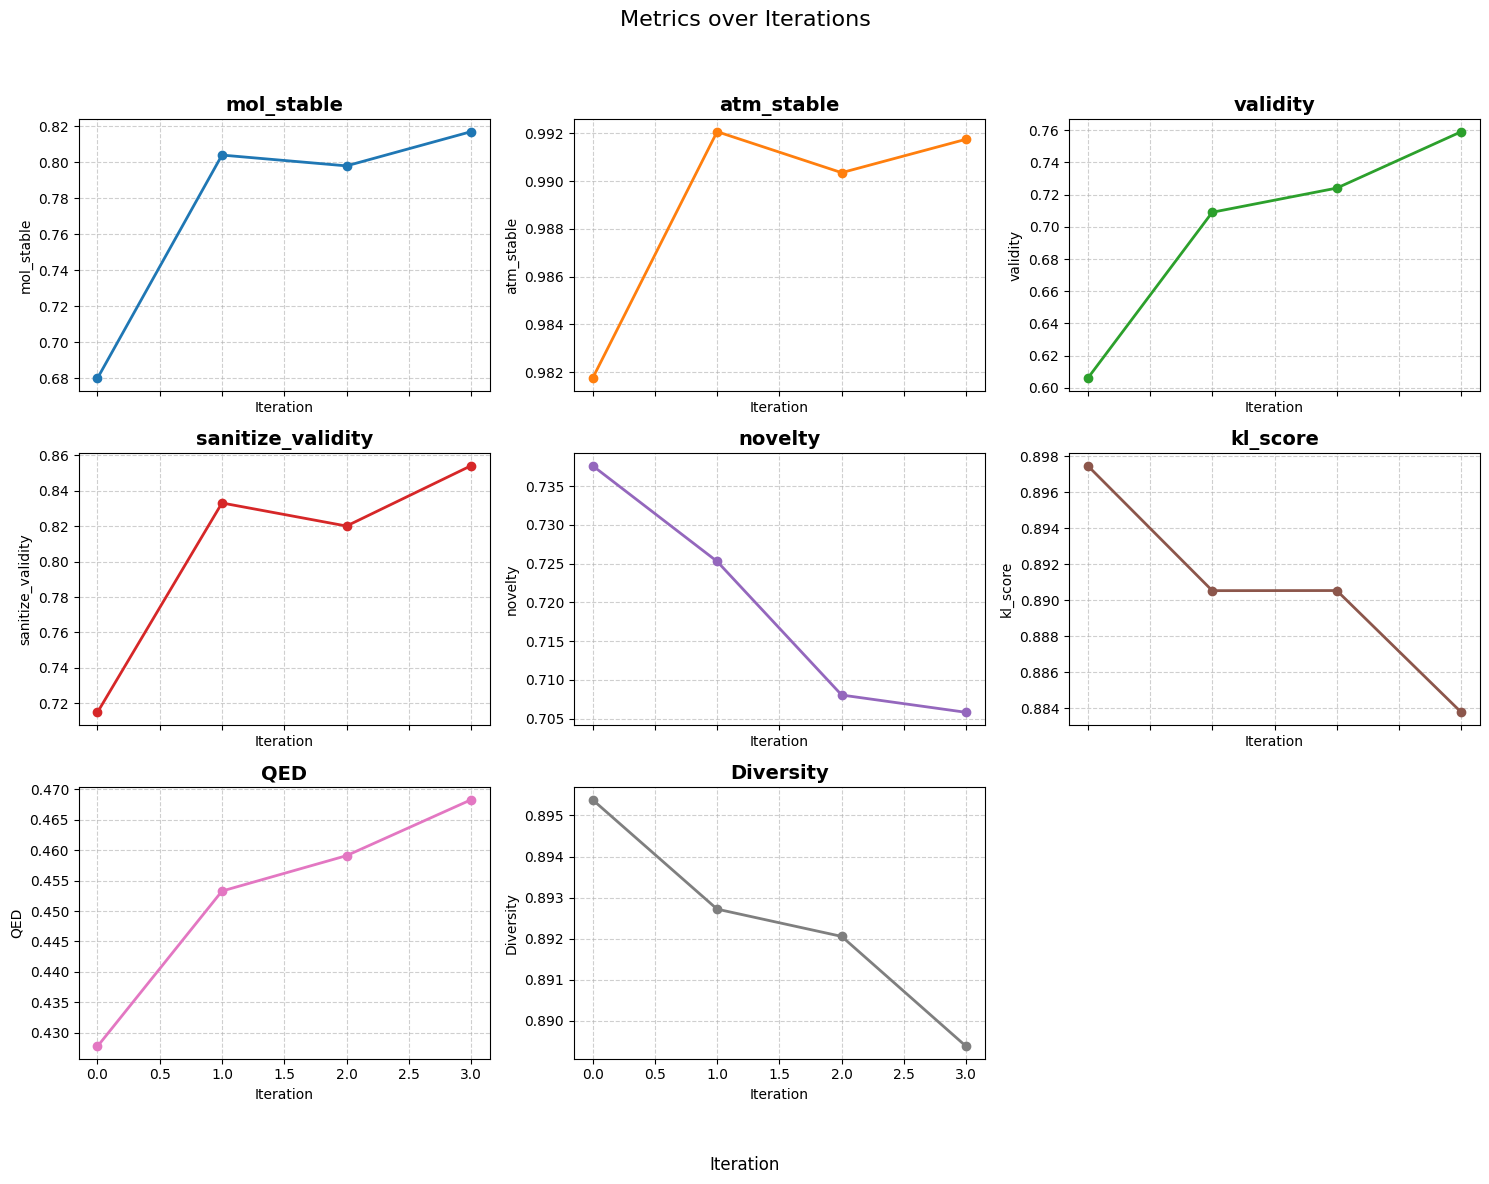

In [29]:
import os
import re

wdirectory = base_dir + "/diffusion_wdir/model_registry"
# Build file_paths automatically and skip missing
file_paths = []
missing_files = []

for folder in sorted(
    [d for d in os.listdir(wdirectory) if re.match(r"model_iter_\d+", d)],
    key=lambda x: int(re.search(r"\d+", x).group())
):
    file_path = os.path.join(wdirectory, folder, "run0", "evaluation.csv")
    if os.path.exists(file_path):
        file_paths.append(file_path)
    else:
        missing_files.append(file_path)

# Now load and plot
df = load_iteration_data_from_paths(file_paths)
metrics = ['mol_stable', 'atm_stable', 'validity', 'sanitize_validity',
           'novelty', 'kl_score', 'QED', 'Diversity']
plot_metrics_subplots(df, metrics)

# Report missing files if any
if missing_files:
    print("⚠ Missing files:")
    for f in missing_files:
        print(f)
